# Learning Matplotlib and Seaborn

## Why should I use Matplotlib and Seaborn?

They are libraries for data visualization, providing simple and powerful tools to create charts and statistical graphics, making it easier to understand and communicate data insights.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

Reading and setting things up

In [3]:
pokemon = pd.read_csv('./csvs/pokemon.csv')
print(pokemon.shape)
pokemon.head(10)

(807, 14)


,id,species,generation_id,height,weight,base_experience,type_1,type_2,hp,attack,defense,speed,special-attack,special-defense
0,1,bulbasaur,1,0.7,6.9,64,grass,poison,45,49,49,45,65,65
1,2,ivysaur,1,1.0,13.0,142,grass,poison,60,62,63,60,80,80
2,3,venusaur,1,2.0,100.0,236,grass,poison,80,82,83,80,100,100
3,4,charmander,1,0.6,8.5,62,fire,NaN,39,52,43,65,60,50
4,5,charmeleon,1,1.1,19.0,142,fire,NaN,58,64,58,80,80,65
5,6,charizard,1,1.7,90.5,240,fire,flying,78,84,78,100,109,85
6,7,squirtle,1,0.5,9.0,63,water,NaN,44,48,65,43,50,64
7,8,wartortle,1,1.0,22.5,142,water,NaN,59,63,80,58,65,80
8,9,blastoise,1,1.6,85.5,239,water,NaN,79,83,100,78,85,105
9,10,caterpie,1,0.3,2.9,39,bug,NaN,45,30,35,45,20,20


### Using seaborn to create a vertical bar graph

Obs: A semicolon (;) at the end of the statement will supress printing the plotting information

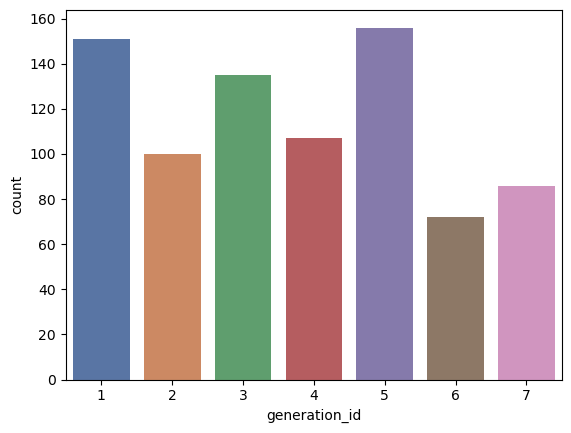

In [4]:
sb.countplot(data=pokemon, x='generation_id', hue='generation_id',palette='deep', legend=False);
plt.show()

Creating a bar chart with a uniform color

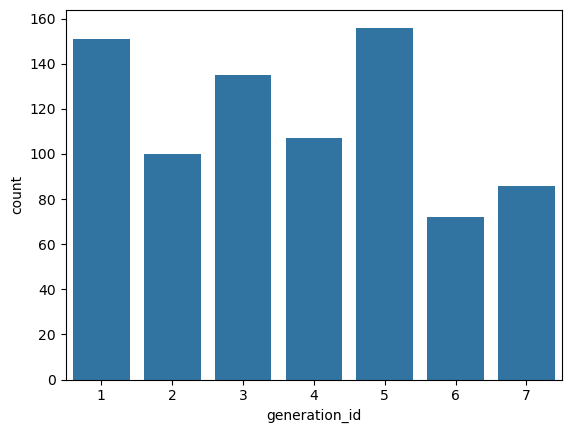

In [5]:
base_color = sb.color_palette()[0]

sb.countplot(data=pokemon, x='generation_id', color=base_color);
plt.show()

Using Matplotlib

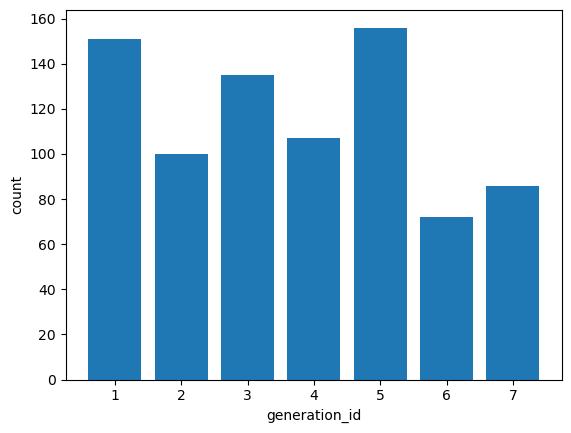

In [6]:
x = pokemon['generation_id'].unique()

y = pokemon['generation_id'].value_counts(sort=False)

plt.bar(x, y)

plt.xlabel('generation_id')
plt.ylabel('count')

plt.show()

Static and dynamic ordering of the bars in a bar chart using seabirb.countplot()

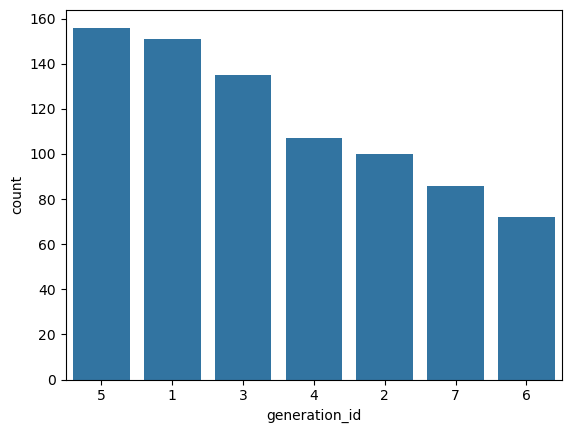

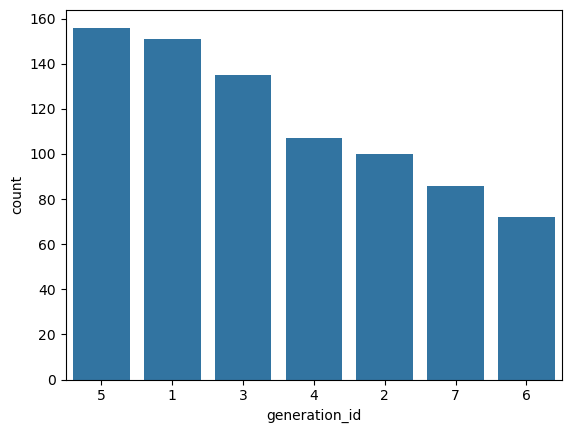

In [7]:
sb.countplot(data=pokemon, x='generation_id', color=base_color, order=[5,1,3,4,2,7,6]);
plt.show()

#OR

freq = pokemon['generation_id'].value_counts()

gen_order = freq.index

sb.countplot(data=pokemon, x='generation_id', color=base_color, order=gen_order);
plt.show()

Rotating the category labels (not axes)

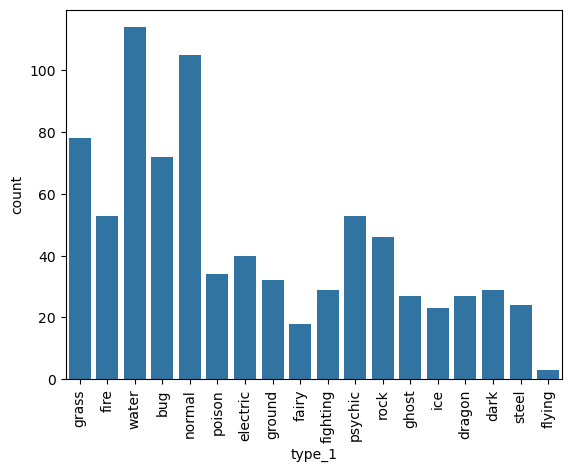

In [8]:
sb.countplot(data=pokemon, x='type_1', color=base_color);

plt.xticks(rotation=90)
plt.show()

Rotating the axes clockwise

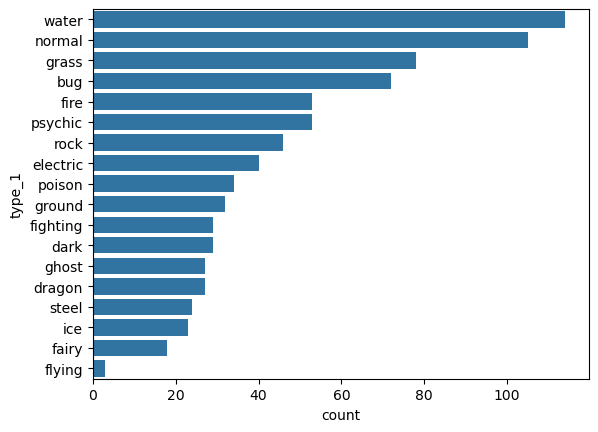

In [9]:
type_order = pokemon['type_1'].value_counts().index
sb.countplot(data=pokemon, y='type_1', color=base_color, order=type_order);
plt.show()

### Absolute vs. Relative Frequency

By default, seaborn's `countplot` function will summarize and plot the data in terms of **absolute frequency**, or pure counts. In certain cases, you might want to understand the distribution of data or want to compare levels in terms of the proportions of the whole. In this case, you will want to plot the data in terms of **relative frequency**, where the height indicates the proportion of data taking each level, rather than the absolute count.

Data Wrangling Step

In [10]:
pkmn_types = pokemon.melt(id_vars=['id', 'species'], 
                          value_vars=['type_1', 'type_2'], 
                          var_name='type_level', 
                          value_name='type')
pkmn_types.head(10)

,id,species,type_level,type
0,1,bulbasaur,type_1,grass
1,2,ivysaur,type_1,grass
2,3,venusaur,type_1,grass
3,4,charmander,type_1,fire
4,5,charmeleon,type_1,fire
5,6,charizard,type_1,fire
6,7,squirtle,type_1,water
7,8,wartortle,type_1,water
8,9,blastoise,type_1,water
9,10,caterpie,type_1,bug


Finding the frequency of unique values in the `type` column

In [11]:
type_counts = pkmn_types['type'].value_counts()
type_counts

type
water       131
normal      109
flying       98
grass        97
psychic      82
bug          77
poison       66
fire         64
ground       64
rock         60
fighting     54
electric     48
fairy        47
steel        47
dark         46
dragon       45
ghost        43
ice          34
Name: count, dtype: int64

In [12]:
type_order = type_counts.index
type_order

Index(['water', 'normal', 'flying', 'grass', 'psychic', 'bug', 'poison',
       'fire', 'ground', 'rock', 'fighting', 'electric', 'fairy', 'steel',
       'dark', 'dragon', 'ghost', 'ice'],
      dtype='str', name='type')

Plotting the horizontal bar charts

<Axes: xlabel='count', ylabel='type'>

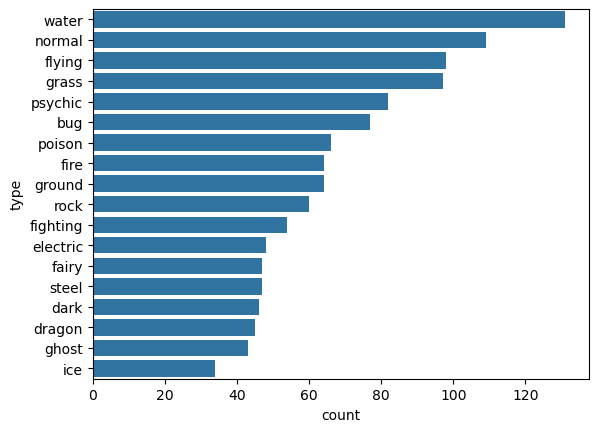

In [13]:
base_color = sb.color_palette()[0]
sb.countplot(data=pkmn_types, y='type', color=base_color, order=type_order)

Plotting a bar chart having the proportions, instead of the actual count, on one of the axes

Finding the max proportion on bar

In [14]:
n_pokemon = pkmn_types['type'].value_counts().sum()

max_type_count = type_counts.iloc[0]

max_prop = max_type_count / n_pokemon
print(max_prop)

0.10808580858085809


Creating an array of evenly spaced, proportioned values

In [15]:
tick_props = np.arange(0, max_prop, 0.02)
tick_props

array([0.  , 0.02, 0.04, 0.06, 0.08, 0.1 ])

Creating a list of String values that can be used as tick labels.

In [16]:
tick_names = ['{:0.2f}'.format(v) for v in tick_props]
tick_names

['0.00', '0.02', '0.04', '0.06', '0.08', '0.10']

Plotting the bar chart, with new x-tick labels

Text(0.5, 0, 'proportion')

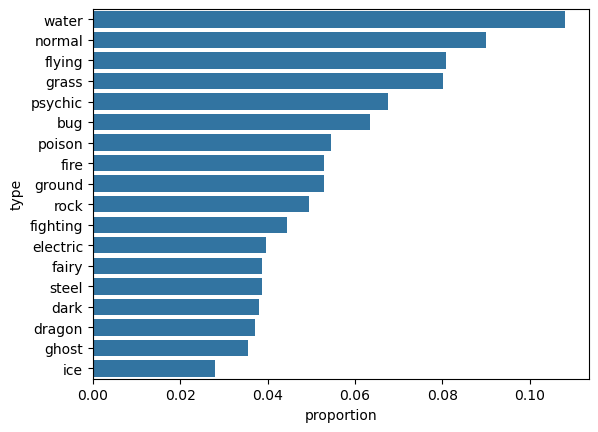

In [17]:
sb.countplot(data=pkmn_types, y='type', color=base_color, order=type_order)

plt.xticks(tick_props * n_pokemon, tick_names)
plt.xlabel('proportion')

Doing it on the horizontal

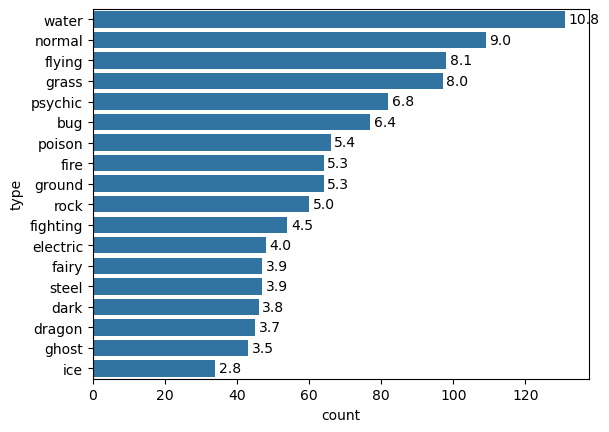

In [18]:
base_color = sb.color_palette()[0]
sb.countplot(data=pkmn_types, y='type', color=base_color, order=type_order)

for i in range (type_counts.shape[0]):
    count = type_counts.iloc[i]
    pct_string = '{:0.1f}'.format(100*count/n_pokemon)
    plt.text(count+1, i, pct_string, va='center')

Print the text (proportion) below the bars of a Vertical plot.

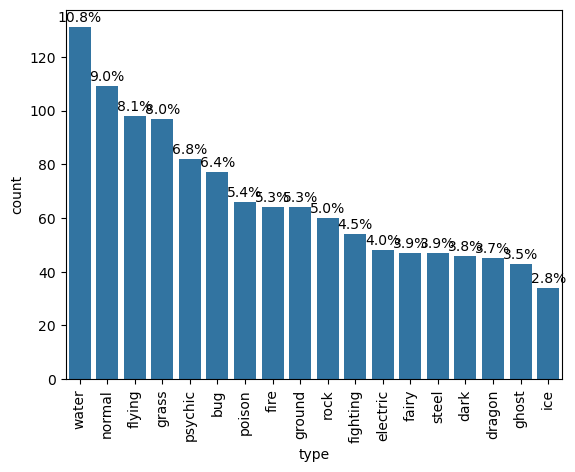

In [19]:
base_color = sb.color_palette()[0]
sb.countplot(data=pkmn_types, x='type', color=base_color, order=type_order)

type_counts = pkmn_types['type'].value_counts()

locs, labels = plt.xticks(rotation=90) 

for loc, label in zip(locs, labels):
    count = type_counts[label.get_text()]
    pct_string = '{:0.1f}%'.format(100*count/n_pokemon)

    plt.text(loc, count+2, pct_string, ha = 'center', color = 'black')

Correcting the sizing

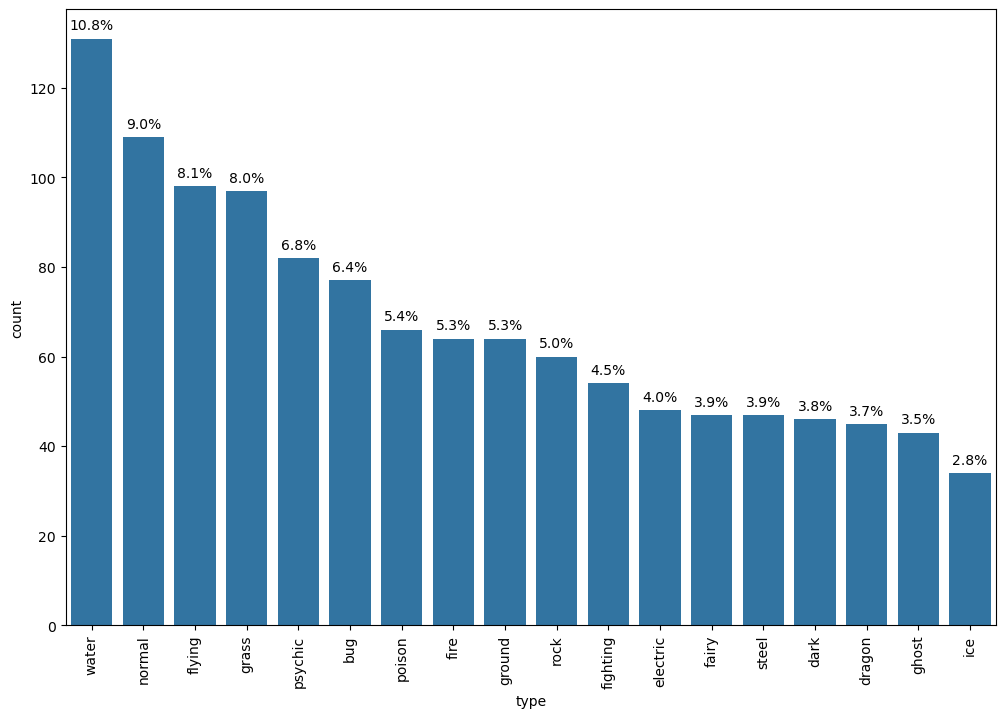

In [20]:
from matplotlib import rcParams
rcParams['figure.figsize'] = 12,8

sb.countplot(data=pkmn_types, x='type', color=base_color, order=type_order)

type_counts = pkmn_types['type'].value_counts()

locs, labels = plt.xticks(rotation=90) 

for loc, label in zip(locs, labels):
    count = type_counts[label.get_text()]
    pct_string = '{:0.1f}%'.format(100*count/n_pokemon)
    plt.text(loc, count+2, pct_string, ha = 'center', color = 'black')

### Counting Missing Data

In [21]:
sales_data = pd.read_csv('./csvs/sales-data.csv')
sales_data.head(10)

print(sales_data.shape)
print(sales_data.isnull())

(8190, 12)
      Store   Date  Temperature  Fuel_Price  MarkDown1  MarkDown2  MarkDown3  \
0     False  False        False       False       True       True       True   
1     False  False        False       False       True       True       True   
2     False  False        False       False       True       True       True   
3     False  False        False       False       True       True       True   
4     False  False        False       False       True       True       True   
...     ...    ...          ...         ...        ...        ...        ...   
8185  False  False        False       False      False      False      False   
8186  False  False        False       False      False      False      False   
8187  False  False        False       False      False      False      False   
8188  False  False        False       False      False      False      False   
8189  False  False        False       False      False      False      False   

      MarkDown4  MarkDown5  

In [22]:
print(sales_data.isna().sum())

Store              0
Date               0
Temperature        0
Fuel_Price         0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64


Preparing a NaN tabular data

In [23]:
na_counts = sales_data.drop(['Date', 'Temperature', 'Fuel_Price'], axis=1).isna().sum()
print(na_counts)

Store              0
MarkDown1       4158
MarkDown2       5269
MarkDown3       4577
MarkDown4       4726
MarkDown5       4140
CPI              585
Unemployment     585
IsHoliday          0
dtype: int64


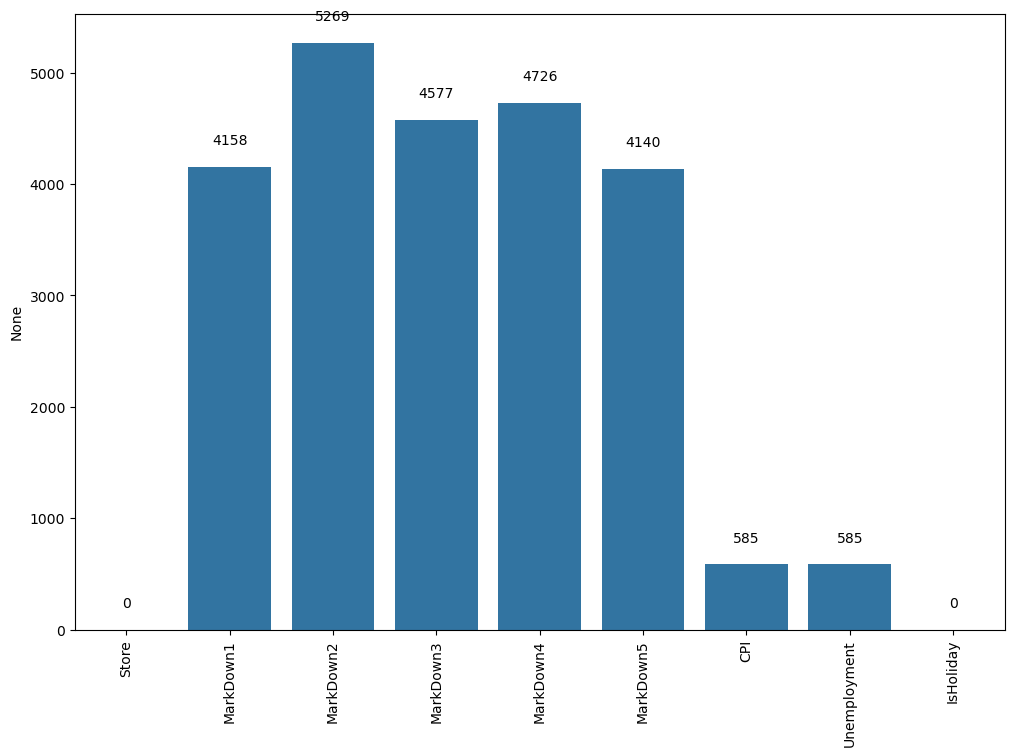

In [24]:
sb.barplot(x=na_counts.index.values, y=na_counts)

plt.xticks(rotation=90) 

for i in range (na_counts.shape[0]):
    count = na_counts.iloc[i]
    plt.text(i, count+300, count, ha = 'center', va='top')

## Pie chart

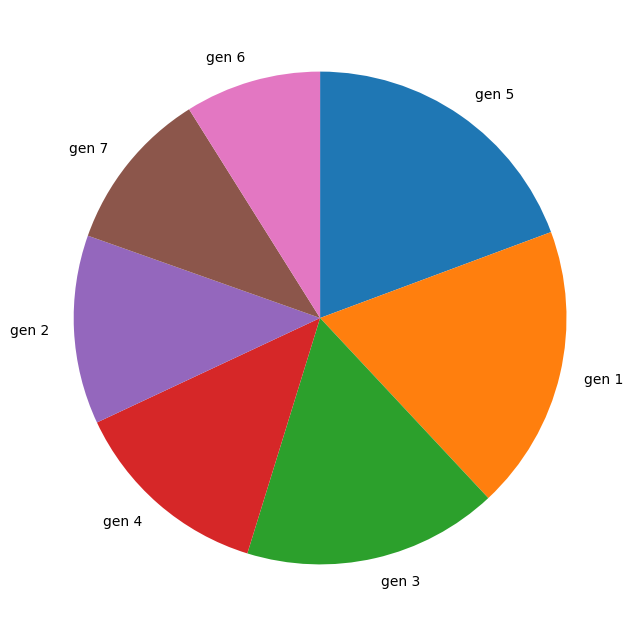

In [26]:
sorted_counts = pokemon['generation_id'].value_counts()

labels = [f"gen {num}" for num in sorted_counts.index]

plt.pie(sorted_counts, labels=labels, startangle=90, counterclock=False);

plt.axis()
plt.show()

## Donut chart

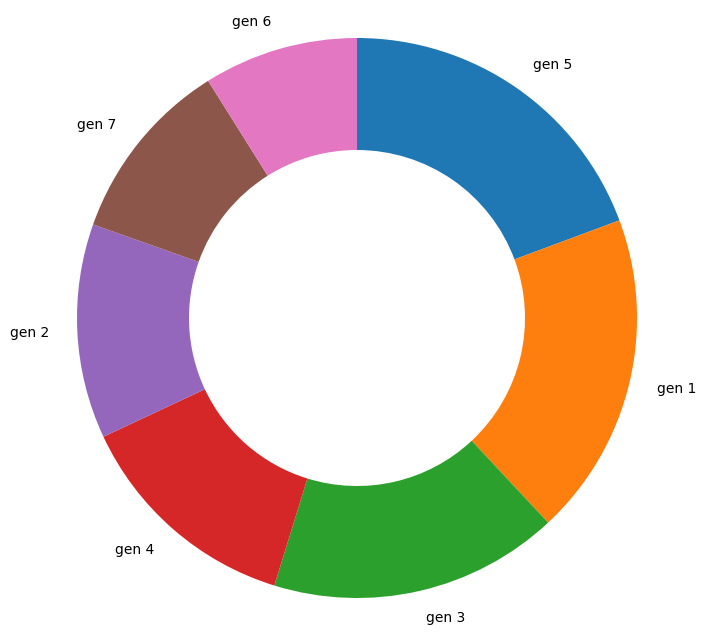

In [27]:
sorted_counts = pokemon['generation_id'].value_counts()

labels = [f"gen {num}" for num in sorted_counts.index]

plt.pie(sorted_counts, labels=labels, startangle=90, counterclock=False, wedgeprops={'width': 0.4});

plt.axis('square')
plt.show()

## Histograms

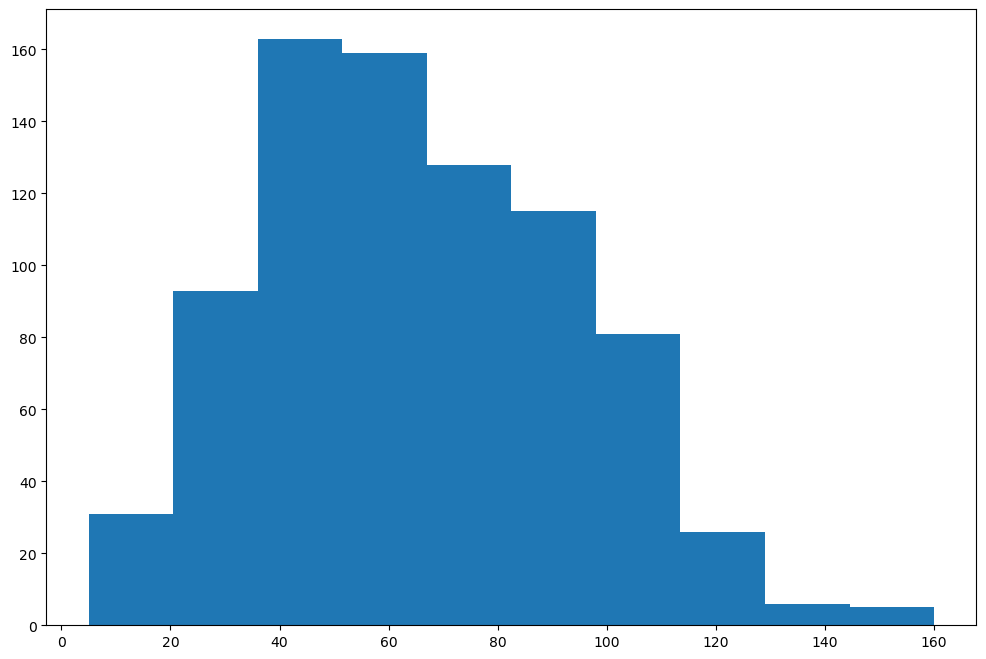

In [28]:
plt.hist(data=pokemon, x='speed')
plt.show()

Changing the bins

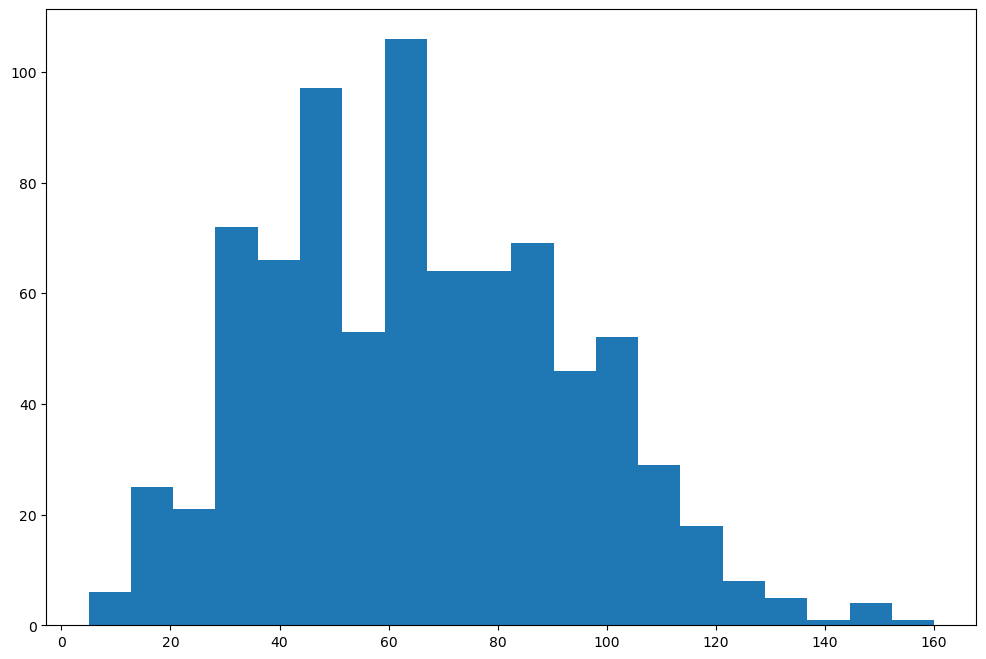

In [29]:
plt.hist(data=pokemon, x='speed', bins=20)
plt.show()

Dynamic number of bins

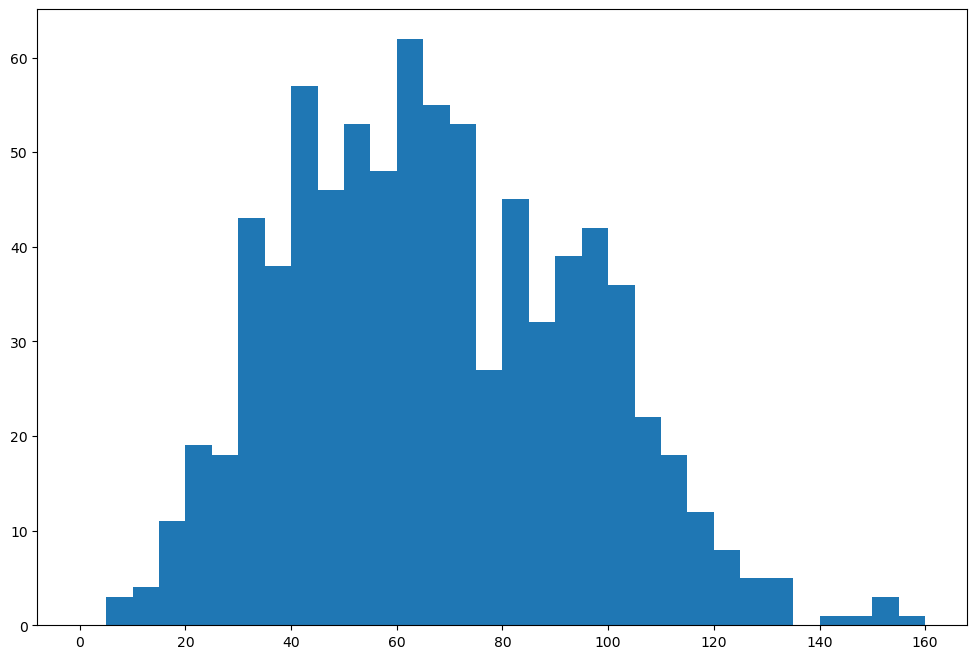

In [30]:
bins = np.arange(0, pokemon['speed'].max() + 5, 5)

plt.hist(data=pokemon, x='speed', bins=bins)
plt.show()

Seaborn's histplot

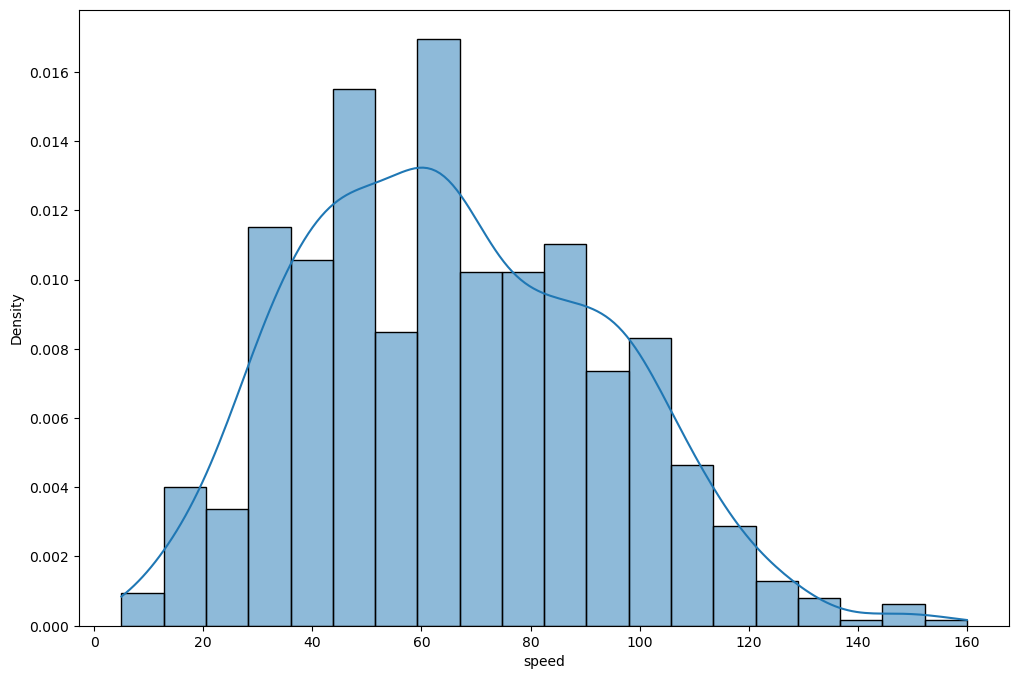

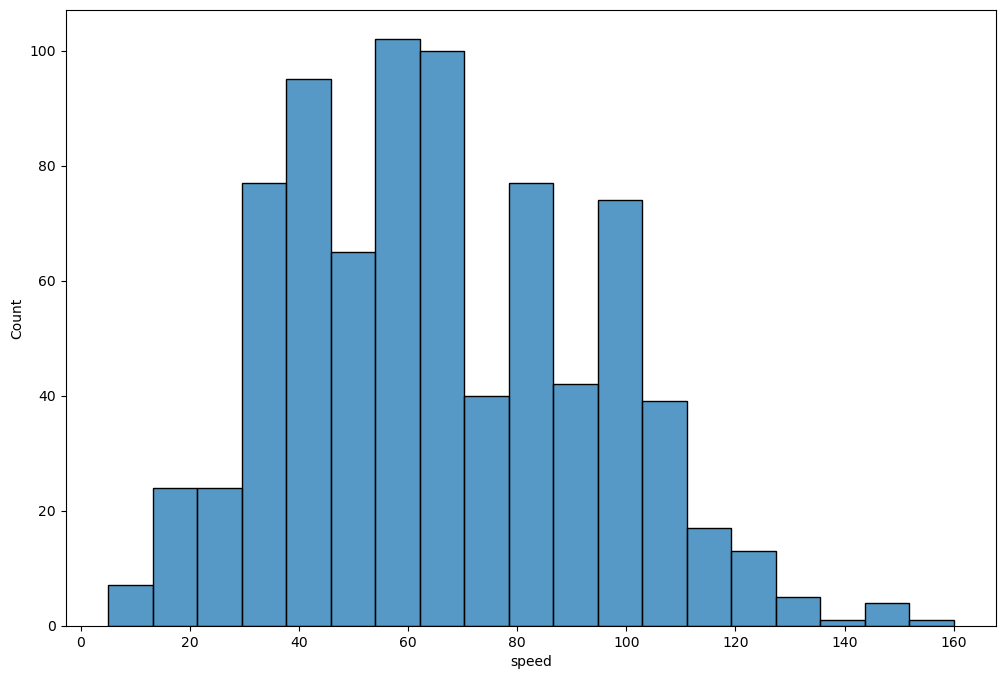

In [31]:
sb.histplot(data=pokemon, x='speed', kde=True, stat='density', bins=20)
plt.show()

#Without KDE line
sb.histplot(data=pokemon, x='speed')
plt.show()

Plotting histograms side-by-side

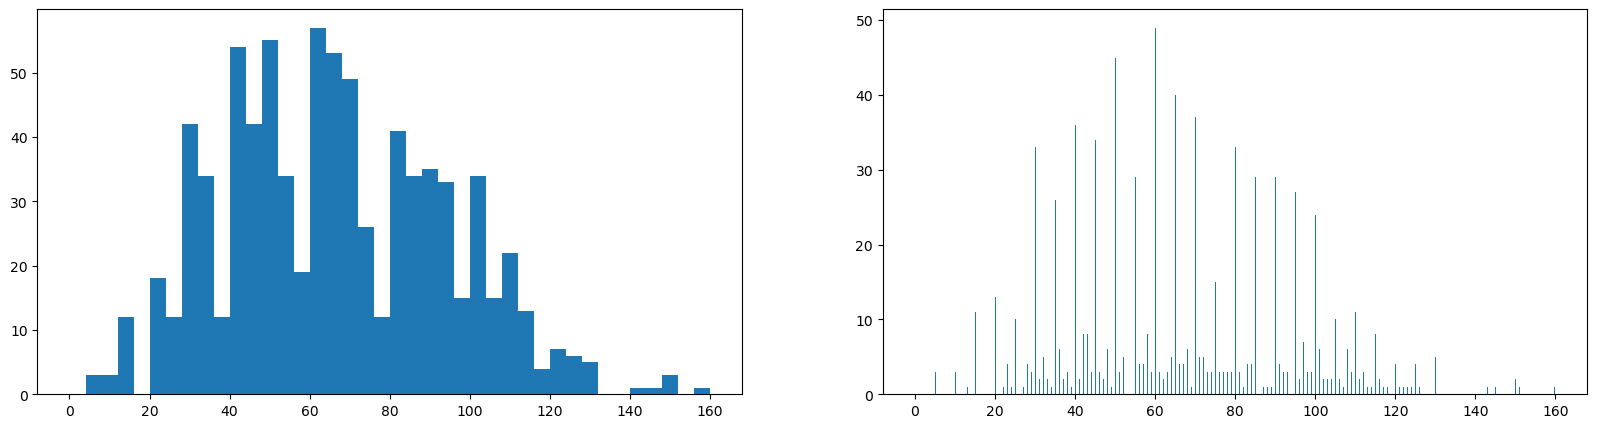

In [33]:
plt.figure(figsize=[20, 5])

plt.subplot(1, 2, 1)
bins = np.arange(0, pokemon['speed'].max() + 4, 4)
plt.hist(data=pokemon, x='speed', bins=bins)

plt.subplot(1, 2, 2)
bins = np.arange(0, pokemon['speed'].max() + 0.25, 0.25)
plt.hist(data=pokemon, x='speed', bins=bins)
plt.show()